# Example of the aitlas toolbox in the context of change detection

## Import the required packages

In [ ]:
from aitlas.datasets import SMARSDataset
from aitlas.utils import image_loader
from aitlas.models import UnetChangeDetection
from aitlas.transforms import MinMaxNormTranspose, ResizeToTensor

## Visualize images and masks

Multilabel mask

Total number of patches: 2


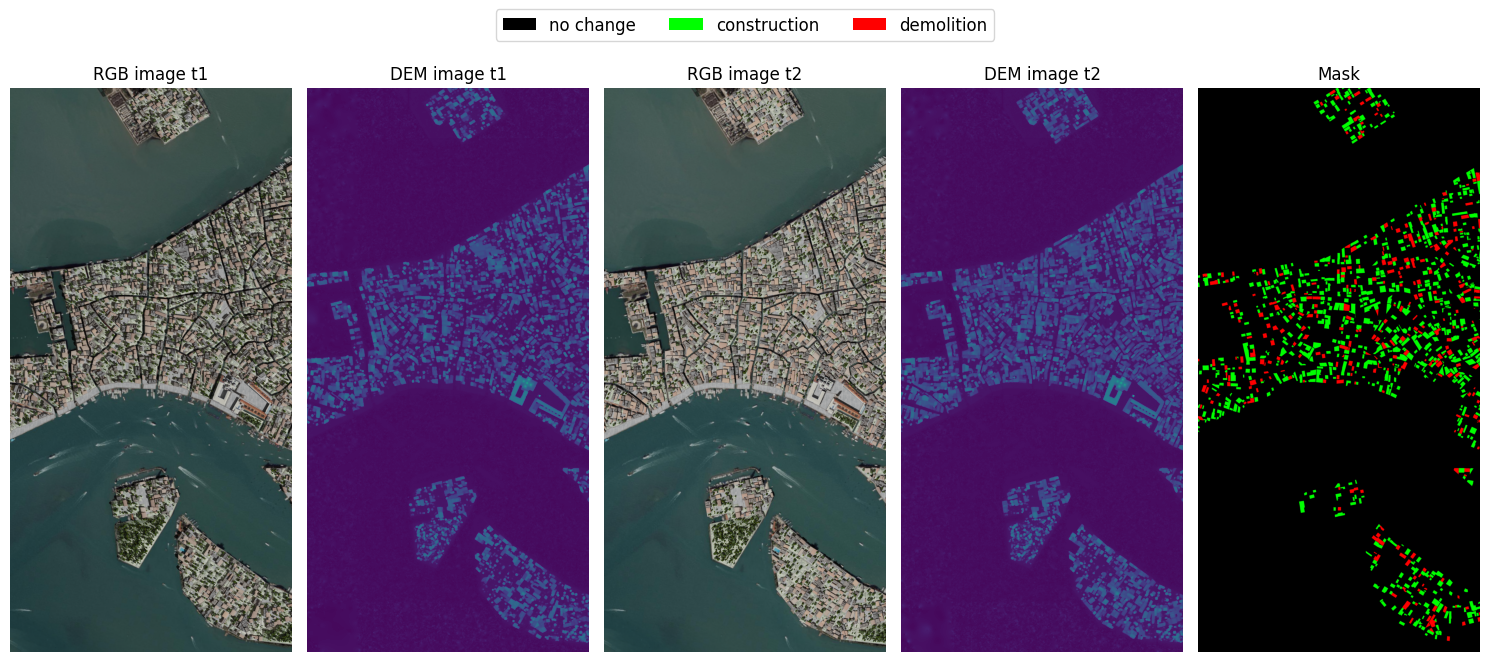

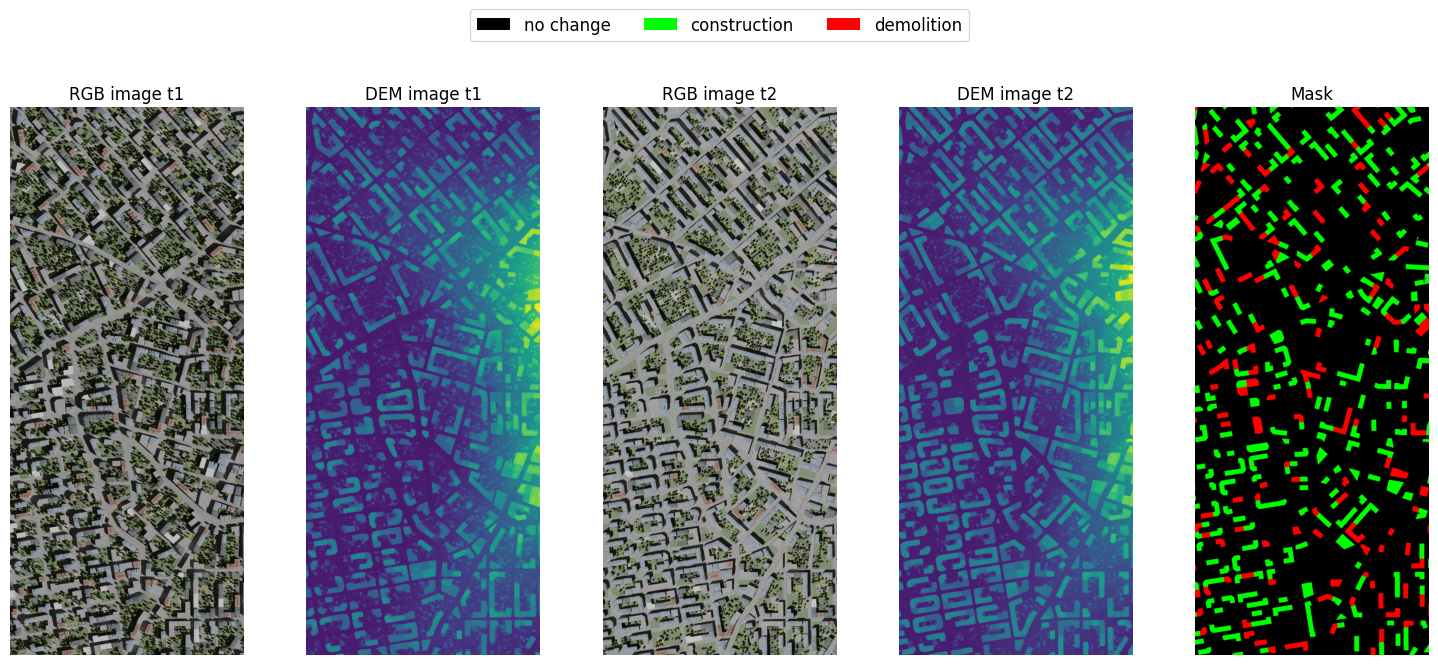

In [ ]:
dataset_config = {
    "data_dir" : "./data/smars/SMARS_Release/",
    "mode": "train",
    "task_type": "multilabel",
    "imagery": "all"
}
dataset = SMARSDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

dataset.show_image(0)
dataset.show_image(1);

In [38]:
dataset.data_distribution_table()

,Number of pixels
no change,4381473.0
construction,695030.0
demolition,327577.0


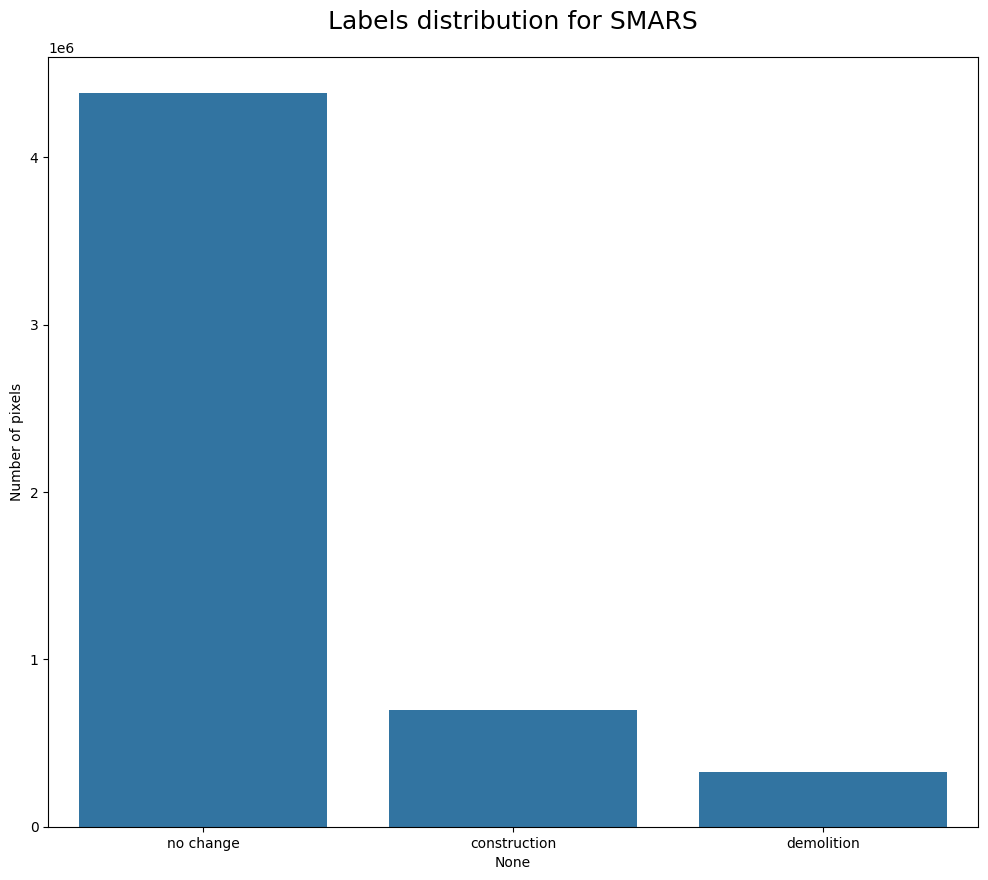

In [39]:
dataset.data_distribution_barchart();

Binary mask

Total number of patches: 2


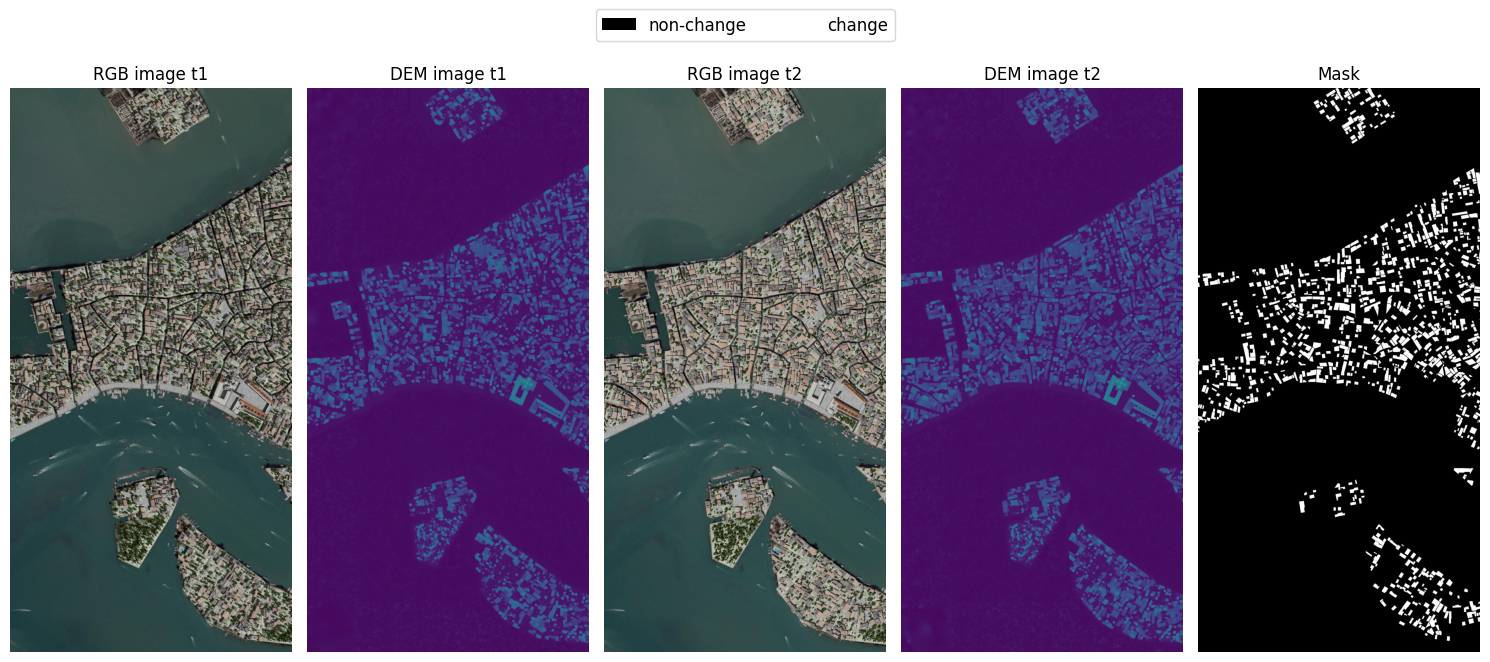

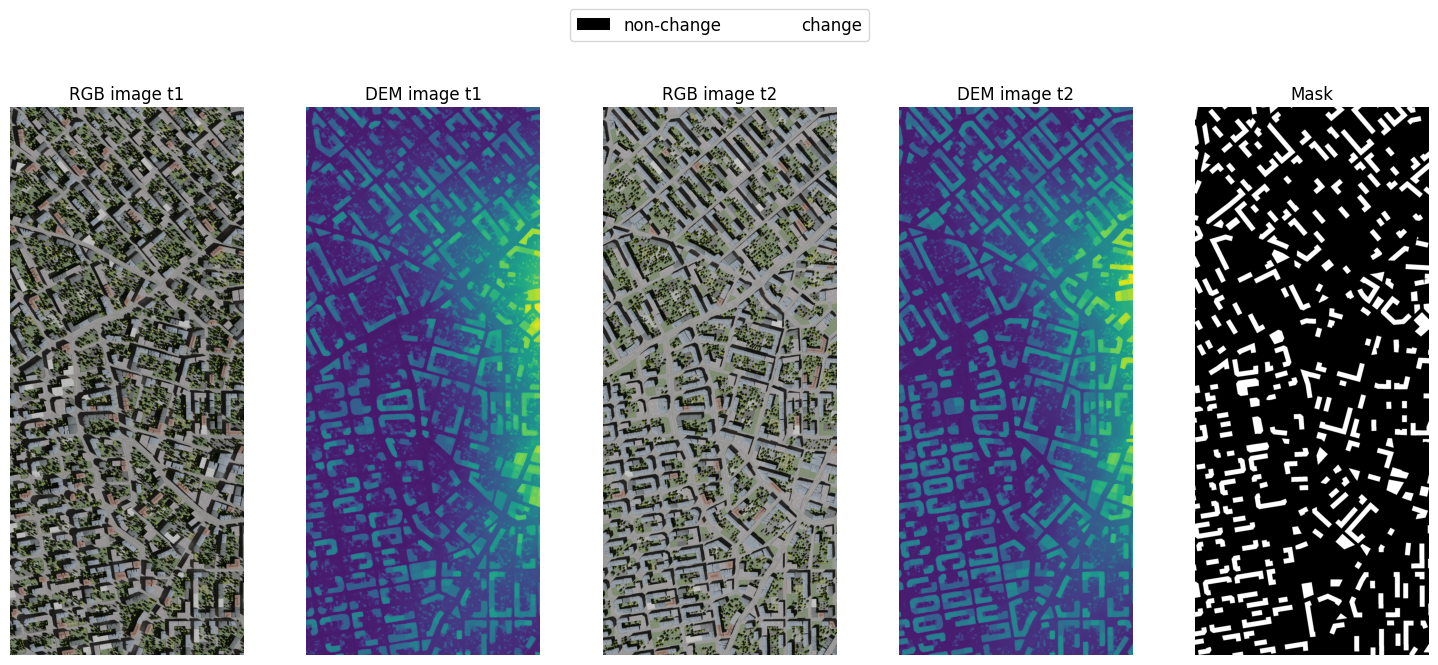

In [ ]:
dataset_config = {
    "data_dir" : "./data/smars/SMARS_Release/",
    "mode": "train",
    "task_type": "binary",
    "imagery": "all"
}
dataset = SMARSDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

dataset.show_image(0)
dataset.show_image(1);

## Load training and test data

In [ ]:
train_dataset_config = {
    "batch_size": 16,
    "shuffle": True,
    "num_workers": 4,
    "data_dir" : "./data/smars/SMARS_Release/",
    "mode": "train",
    "task_type": "binary",
    "imagery": "rgb",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
train_dataset = SMARSDataset(train_dataset_config)

test_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "num_workers": 4,
    "data_dir" : "./data/smars/SMARS_Release/",
    "mode": "val",
    "task_type": "binary",
    "imagery": "rgb",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
test_dataset = SMARSDataset(test_dataset_config)
len(train_dataset), len(test_dataset)

(2, 2)

## Create the model

In [ ]:
epochs = 50
model_directory = "./data/experiments/smars"
model_config = {
    "num_classes": 2, 
    "learning_rate": 0.0001,
    "pretrained": False, 
    "threshold": 0.5,
    "metrics": ["accuracy", "precision", "recall", "f1_score", "iou"]
}

model = UnetChangeDetection(model_config)
model.prepare()

## Start the training

In [69]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1',
)

model_path = model_directory + "/checkpoint.pth.tar"
model.load_model(model_path)
model.running_metrics.reset()
model.evaluate(dataset=test_dataset, model_path=model_path)
test_metrics = model.running_metrics.get_scores(model.metrics)

2026-01-29 11:15:07,566 INFO Starting training.
training: 100%|██████████| 1/1 [00:03<00:00,  3.15s/it]
2026-01-29 11:15:10,765 INFO epoch: 1, loss:  0.28871
testing on train set: 100%|██████████| 1/1 [00:02<00:00,  2.89s/it]
2026-01-29 11:15:14,802 INFO Accuracy:0.8428840637207031, Accuracy per Class:[0.71652222 0.96924591], Precision Micro:0.716522216796875, Precision Macro:0.3582611083984375, Precision Weighted:0.6870338092304544, Precision per Class:[0.71652222 0.        ], Recall Micro:0.9588450896913637, Recall Macro:0.5, Recall Weighted:0.9588450896913637, Recall per Class:[1. 0.], F1_score Micro:0.8201590261070038, F1_score Macro:0.41742670720216163, F1_score Weighted:0.8004950970136546, F1_score per Class:[0.83485341 0.        ], IOU:0.6951437051730902, IOU mean:0.3582611083984375, IOU per Class:[0.71652222 0.        ]
training: 100%|██████████| 1/1 [00:02<00:00,  2.79s/it]
2026-01-29 11:15:17,598 INFO epoch: 2, loss:  0.28262
testing on train set: 100%|██████████| 1/1 [00:02<

## Predictions

2026-01-29 11:54:28,415 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/smars/checkpoint.pth.tar
2026-01-29 11:54:28,745 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/smars/checkpoint.pth.tar at epoch 51


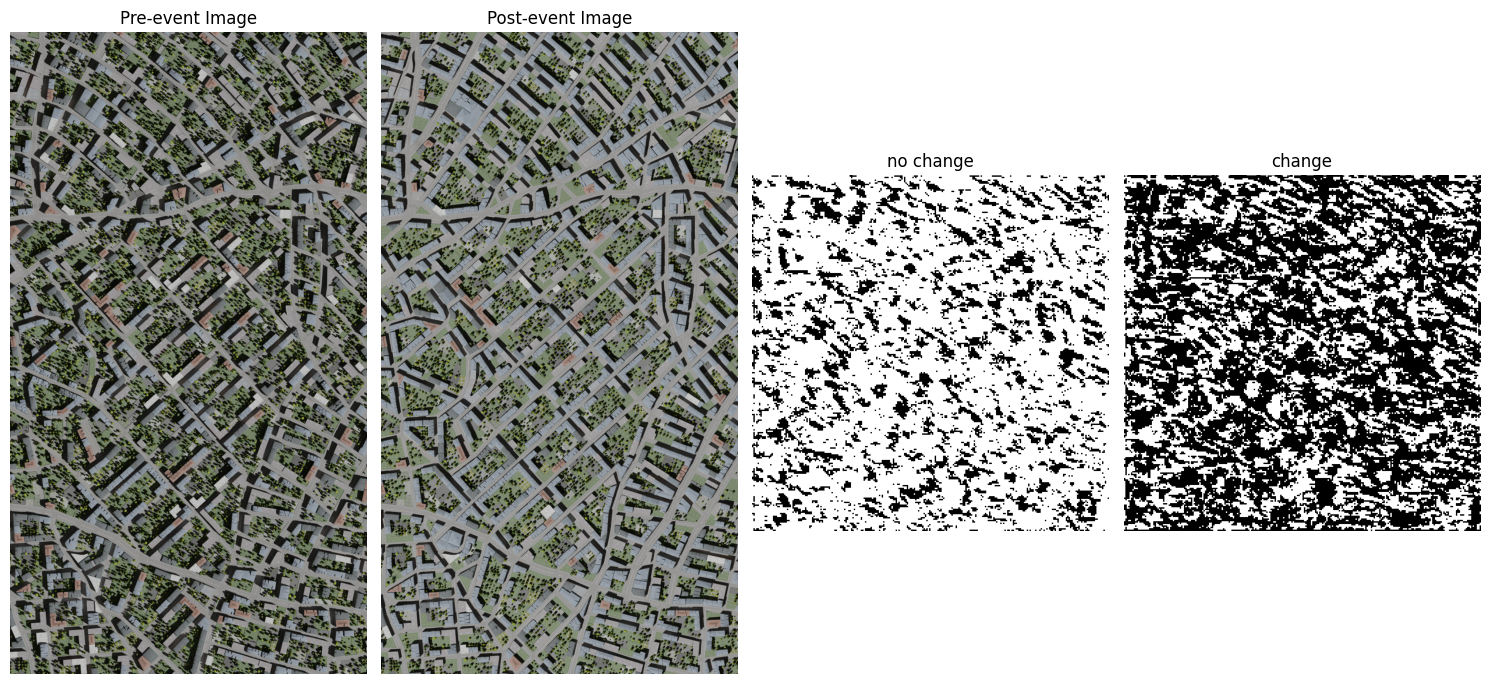

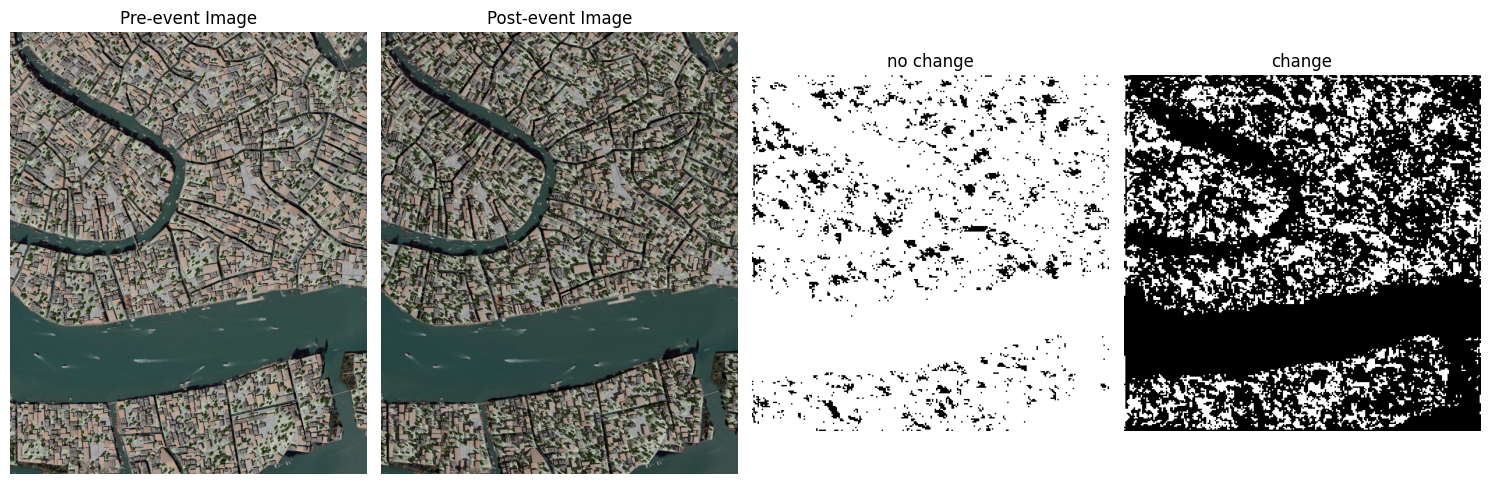

In [ ]:
model_path = "./data/experiments/smars/checkpoint.pth.tar"
labels = ["no change","change"]
transform = ResizeToTensor()
model.load_model(model_path)

image1 = image_loader("./data/smars/SMARS_Release/SParis/50cm/pre/splitting/test/SParis_50cm_pre_test.tif")
image2 = image_loader("./data/smars/SMARS_Release/SParis/50cm/post/splitting/test/SParis_50cm_post_test.tif")
fig = model.predict_masks(image1, image2, labels, transform)

image1 = image_loader("./data/smars/SMARS_Release/SVenice/50cm/post/splitting/test/SVenice_50cm_post_test.tif")
image2 = image_loader("./data/smars/SMARS_Release/SVenice/50cm/pre/splitting/test/SVenice_50cm_pre_test.tif")
fig = model.predict_masks(image1, image2, labels, transform)